# Data Visualization

In [3]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt

## Model Comparison

Function to plot avg. Acc on training sets

In [4]:
# Function to read CSV files, calculate column means, and plot the data
def read_and_plot(file_paths, labels, title):
    plt.figure(figsize=(12, 6))
    final_mean = {}
    # Loop through each file, calculate the mean, and plot it
    for i, file in enumerate(file_paths):
        # Read the CSV file into a pandas DataFrame
        df = pd.read_csv(file, header=None)
        
        # The first column is the label, ignore it for calculation
        data = df.iloc[:, 1:]
        
        # Calculate the mean of each column
        column_means = data.mean(axis=0)
        
        # Plot the mean values as a line
        plt.plot(column_means, marker='o', label=labels[i])
        final_mean[labels[i]] = column_means[len(column_means)-1]   # Store the final mean value for each model
    # Add title and labels
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Mean Accuracy')
    
    # Show legend to distinguish between the lines
    plt.legend()
    
    # Display the plot
    plt.show()
    return final_mean

### IP-Hardness Dataset

Avg. training accuracy

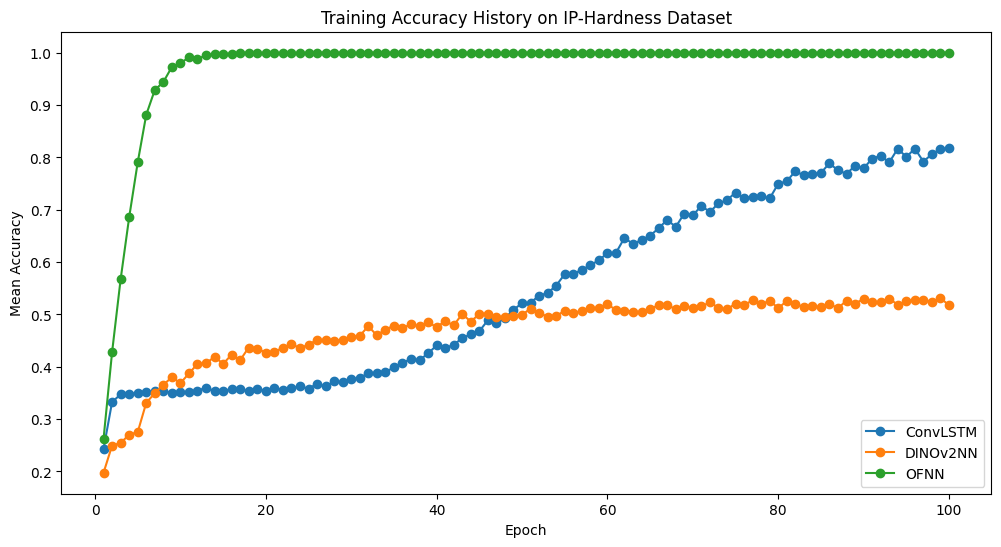

{'ConvLSTM': 0.8159999972581864, 'DINOv2NN': 0.5312000000476838, 'OFNN': 1.0}

In [5]:


# File paths and corresponding labels
file_paths = [
    'metrics\Comp_Model_Aug_11_hardness_ConvLSTM_train_accuracy_history.csv',
    'metrics\Comp_Model_Aug_12_hardness_DINOKeras_train_accuracy_history.csv',
    'metrics\Comp_Model_Aug_11_hardness_OpticalFlowNN_train_accuracy_history.csv'
]



labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']

# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Training Accuracy History on IP-Hardness Dataset")

Avg. validation accuracy

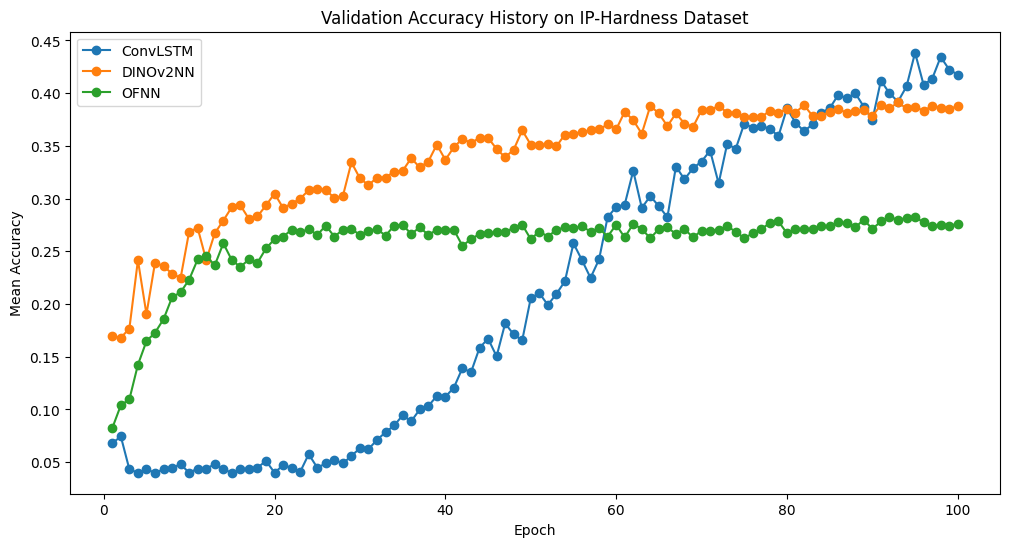

{'ConvLSTM': 0.4224000018835068,
 'DINOv2NN': 0.38479998871684074,
 'OFNN': 0.2743999969959259}

In [6]:
# File paths and corresponding labels
file_paths = [
    'metrics\Comp_Model_Aug_11_hardness_ConvLSTM_val_accuracy_history.csv',
    'metrics\Comp_Model_Aug_12_hardness_DINOKeras_val_accuracy_history.csv',
    'metrics\Comp_Model_Aug_11_hardness_OpticalFlowNN_val_accuracy_history.csv'
]



labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']

# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Validation Accuracy History on IP-Hardness Dataset")

### Yuan Dataset

Avg. training accuracy

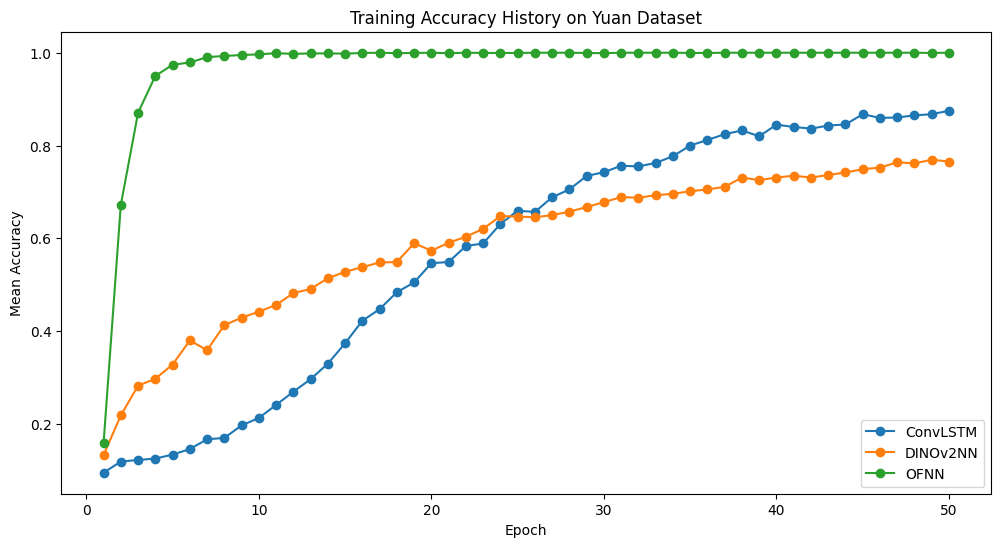

{'ConvLSTM': 0.8675000035762787,
 'DINOv2NN': 0.7695000022649765,
 'OFNN': 0.9995000004768372}

In [7]:
# File paths and corresponding labels
file_paths = [
    'metrics/Comp_Model_Aug_10_final_yuan_ConvLSTM_train_accuracy_history.csv',
    'metrics/Comp_Model_Aug_12_yuan_DINOKeras_train_accuracy_history.csv',
    'metrics/Comp_Model_Aug_10_final_yuan_OpticalFlowNN_train_accuracy_history.csv'
]

labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']

# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Training Accuracy History on Yuan Dataset")

Avg. validation accuracy

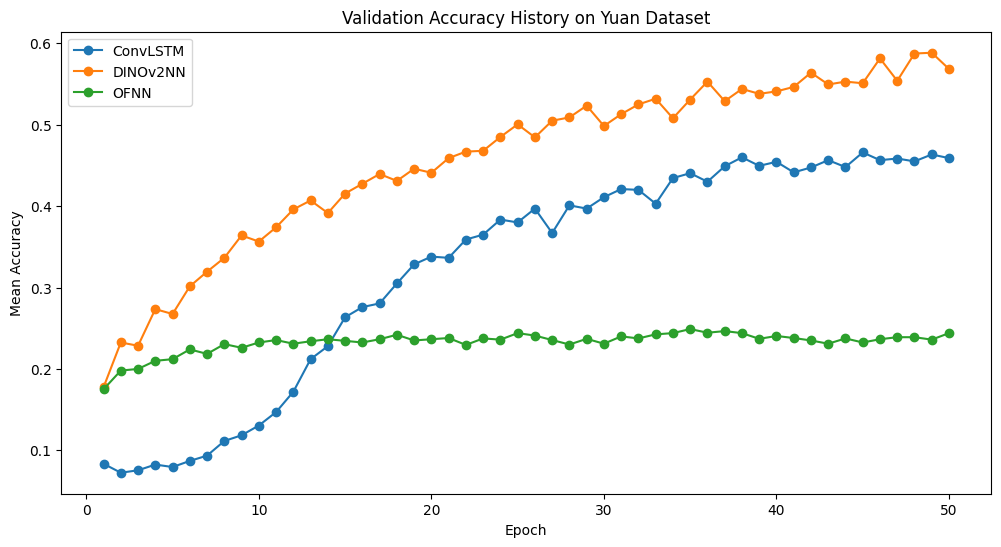

{'ConvLSTM': 0.46349999770522116,
 'DINOv2NN': 0.5884999960660935,
 'OFNN': 0.23600000195205212}

In [8]:
# File paths and corresponding labels
file_paths = [
    'metrics/Comp_Model_Aug_10_final_yuan_ConvLSTM_val_accuracy_history.csv',
    'metrics/Comp_Model_Aug_12_yuan_DINOKeras_val_accuracy_history.csv',
    'metrics/Comp_Model_Aug_10_final_yuan_OpticalFlowNN_val_accuracy_history.csv'
]

labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']

# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Validation Accuracy History on Yuan Dataset")

## Adaptive Sampling 

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_metrics_for_strats(filename, strats, metric):
    # 0. Read the file
    df = pd.read_csv(filename, header=None)

    plt.figure(figsize=(14, 8))  # Increase the figure size to accommodate the table

    for strat in strats:
        # 1. Filter rows where the first column contains the string `strat`
        filtered_df = df[df[0].str.contains(strat, na=False)]

        # 2. Compute the mean of each column (excluding the first one, which is the row identifier)
        mean_values = filtered_df.iloc[:, 1:].mean()

        # 3. Plot a line for the current strat
        plt.plot(range(len(mean_values)), mean_values, marker='o', label=strat)

        # Prepare the DataFrame for display as a table
        mean_table = pd.DataFrame(mean_values, columns=[strat])
        print(f"Mean values for {strat}:")
        print(mean_table)
        print("\n")

        # Add the table to the plot (use loc='bottom' to place it below the chart)
        plt.table(cellText=mean_table.values, 
                  colLabels=mean_table.columns, 
                  rowLabels=[f'Iteration {i}' for i in range(len(mean_values))], 
                  loc='bottom', cellLoc='center')

    # Adjust the layout to make room for the table
    plt.subplots_adjust(left=0.2, bottom=0.3)

    # Finalize the plot
    plt.title(f'Line Chart of {metric} for Different Strategies')
    plt.xlabel('Iterations')
    plt.ylabel(metric)
    plt.xticks(range(len(mean_values)))  # Set X-axis ticks to match the iteration indices
    plt.legend(title='Strategy')
    plt.grid(True)
    plt.show()

# Example usage:
# strats = ['entropy_leave_[87]_out', 'another_strat']
# plot_metrics_for_strats('data.csv', strats, 'Some Metric')


## Yuan Dataset w/ DinoV2NN

Mean values for entropy:
       Mean
1  0.697778
2  0.800000
3  0.826667
4  0.857778
5  0.915556
6  0.897778


Mean values for variance:
       Mean
1  0.684444
2  0.795556
3  0.875556
4  0.915556
5  0.946667
6  0.968889


Mean values for random:
       Mean
1  0.773333
2  0.800000
3  0.817778
4  0.866667
5  0.866667
6  0.893333




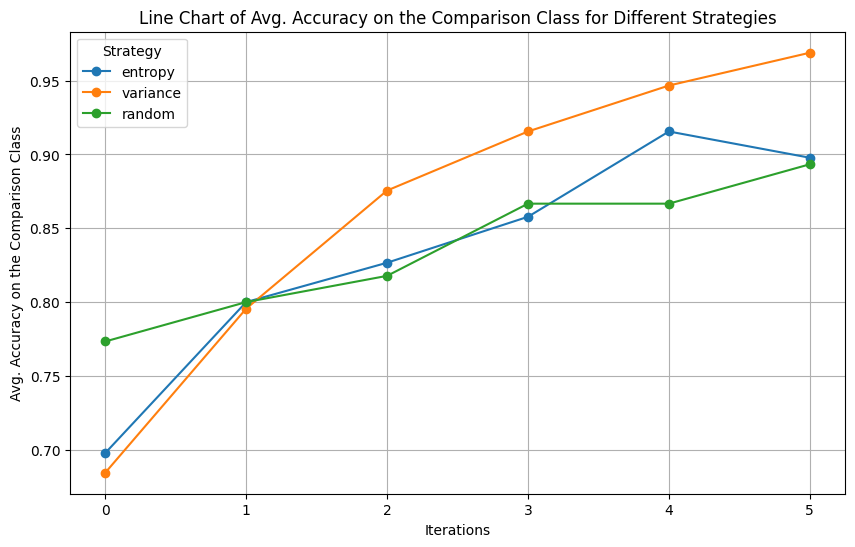

In [15]:
strats = ['entropy', 'variance', 'random']
plot_metrics_for_strats('metrics\exp\Final_exp_Aug_12_yuan_DINOKeras_acc_comp_history.csv', strats, 'Avg. Accuracy on the Comparison Class')

Mean values for entropy:
       Mean
1  3.671111
2  2.217778
3  1.986667
4  1.391111
5  0.844444
6  0.973333


Mean values for variance:
       Mean
1  3.511111
2  2.071111
3  1.297778
4  1.115556
5  0.595556
6  0.506667


Mean values for random:
       Mean
1  2.773333
2  2.262222
3  2.728889
4  1.626667
5  1.760000
6  1.186667




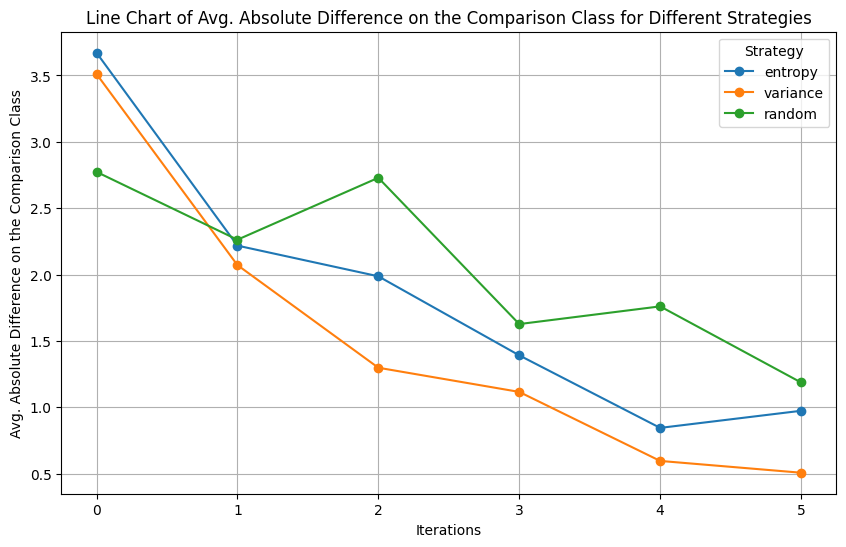

In [18]:
plot_metrics_for_strats('metrics\exp\Final_exp_Aug_12_yuan_DINOKeras_abs_diff_comp_history.csv', strats, 'Avg. Absolute Difference on the Comparison Class')


## Domain Expansion

C:\Users\bnkrg\AppData\Local\Temp\ipykernel_27864\1962203830.py:27: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x_smooth, y_smooth, label=row[0])


<module 'matplotlib.pyplot' from 'c:\\Python310\\lib\\site-packages\\matplotlib\\pyplot.py'>

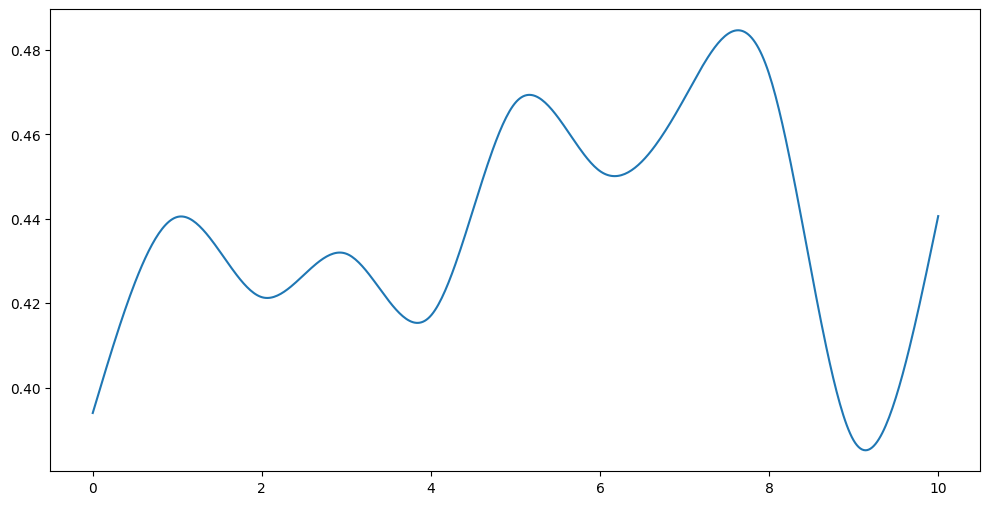

In [11]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import CubicSpline

# Function to interpolate using cubic splines and plot each row as a separate curve
def read_and_plot_smoothed_curves(csv_file):
    # Read the CSV file into a pandas DataFrame
    df = pd.read_csv(csv_file)
    
    plt.figure(figsize=(12, 6))
    
    for index, row in df.iterrows():
        # Extract iteration indices and values
        x = np.arange(len(row[1:]))  # x-coordinates (iteration indices)
        y = row[1:].values          # y-coordinates (values)
        
        # Perform cubic spline interpolation
        cs = CubicSpline(x, y, bc_type='natural')
        
        # Generate a smooth curve
        x_smooth = np.linspace(x.min(), x.max(), 500)  # 500 points for smooth curve
        y_smooth = cs(x_smooth)
        
        # Plot the smooth curve
        plt.plot(x_smooth, y_smooth, label=row[0])
        return plt
    
    plt.title('Mean Accuracy Each Iteration')
    plt.xlabel('Iteration Index')
    plt.ylabel('Mean Accuracy')
    plt.legend()
    plt.show()

# Example usage: replace 'data.csv' with your actual CSV file path
read_and_plot_smoothed_curves('domain_expansion.csv')
